# PjBL2 – Classificador de doenças do milho (MobileNetV2)

**Disciplina:** Sistemas de Informação Inteligentes (PUCPR) – PjBL2
**Papel no projeto:** **segundo modelo**, com o mesmo procedimento da batata (Quadro 1 e etapa 3 do Quadro 3 do plano).
**Objetivo:** criar, treinar e avaliar um modelo de visão computacional que classifica folhas de milho em **4 categorias**:

| Índice | Classe (nome da pasta no PlantVillage) | Significado |
|---|---|---|
| 0 | `Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot` | cercosporiose / mancha-cinzenta (*Cercospora zeae-maydis*) |
| 1 | `Corn_(maize)___Common_rust_` | ferrugem-comum (*Puccinia sorghi*) |
| 2 | `Corn_(maize)___Northern_Leaf_Blight` | helmintosporiose / queima-de-turcicum (*Exserohilum turcicum*) |
| 3 | `Corn_(maize)___healthy` | folha saudável |

Roteiro deste notebook (atende aos 4 itens do enunciado):
1. **Base de imagens**: PlantVillage, pasta `color` (baixada por `scripts/baixar_dados.sh`).
2. **Protocolo experimental**: divisão estratificada 70/15/15 com semente 42, feita por `scripts/preparar_dados.py` **antes** de qualquer aumento de dados.
3. **Modelo**: MobileNetV2 pré-treinada na ImageNet (transferência de aprendizado), treinada em 2 etapas.
4. **Métricas**: matriz de confusão, precisão, revocação, F1 por classe, acurácia e médias macro, no conjunto de **teste usado uma única vez**.

Ao final, o limiar de confiança é calibrado na validação. O modelo é exportado para `modelos/milho.onnx` no mesmo formato do modelo da batata. **Atenção:** o app (`app/inferencia.py`) ainda não tem lista de classes para o milho e sempre carrega `batata.onnx`. Ligar este modelo ao app fica para o TDE2; a ordem correta das classes está em `modelos/metricas_milho.json`.

> Execução: `pip install -r requirements-treino.txt`, depois `bash scripts/baixar_dados.sh milho`, `python scripts/preparar_dados.py milho` e, por fim, este notebook. Roda em CPU ou no Colab.

## 0. Configuração e reprodutibilidade
Fixamos as sementes (Python, NumPy e PyTorch) para que os resultados possam ser reproduzidos.

In [1]:
import json, os, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_recall_fscore_support)

INICIO = time.time()
SEMENTE = 42
random.seed(SEMENTE); np.random.seed(SEMENTE); torch.manual_seed(SEMENTE)
torch.set_num_threads(os.cpu_count() or 4)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PLANTA = "milho"
# Raiz do repositório: primeira pasta acima que contém scripts/preparar_dados.py
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "preparar_dados.py").exists())
SPLITS = RAIZ / "dados" / "splits" / PLANTA
MODELOS = RAIZ / "modelos"; MODELOS.mkdir(exist_ok=True)

# Ordem das classes = ordem alfabética das pastas (a mesma de scripts/preparar_dados.py).
# Esta ordem é a ordem das saídas do modelo e do ONNX.
CLASSES = [
    'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
    'Corn_(maize)___Common_rust_',
    'Corn_(maize)___Northern_Leaf_Blight',
    'Corn_(maize)___healthy',
]
IDX = {c: i for i, c in enumerate(CLASSES)}
curto = lambda c: c.split("___")[1].replace("_", " ").strip()   # nome curto para os gráficos
print("Dispositivo:", DISPOSITIVO, "| threads:", torch.get_num_threads(), "| torch", torch.__version__)

Dispositivo: cpu | threads: 8 | torch 2.14.1+cpu


## 1. Base de imagens e divisão (protocolo experimental)
A divisão já foi gerada por `scripts/preparar_dados.py` e salva em `dados/splits/milho/*.csv`.
Usar listas fixas em CSV garante que treino, validação e teste são sempre os mesmos.

A cercosporiose tem menos imagens (513) que as demais classes (985 a 1192): a base é **moderadamente desbalanceada**.
Para compensar o desbalanceamento, usamos **pesos de classe** na função de perda (opção prevista na Seção 4.1 do plano).

In [2]:
treino_completo = pd.read_csv(SPLITS / "treino.csv")
treino = pd.read_csv(SPLITS / "treino.csv")       # lista efetivamente usada no treino
validacao = pd.read_csv(SPLITS / "validacao.csv")
teste = pd.read_csv(SPLITS / "teste.csv")

contagem = pd.DataFrame({n: d["classe"].value_counts().reindex(CLASSES)
                         for n, d in [("treino (divisão)", treino_completo), ("treino usado", treino),
                                      ("validacao", validacao), ("teste", teste)]}).fillna(0).astype(int)
contagem.loc["total"] = contagem.sum()
# Conferências: treino usado é subconjunto do treino; nenhuma imagem aparece em dois conjuntos
assert set(treino.caminho) <= set(treino_completo.caminho)
assert not (set(treino_completo.caminho) & set(validacao.caminho) or set(treino_completo.caminho) & set(teste.caminho)
            or set(validacao.caminho) & set(teste.caminho))
contagem

,treino (divisão),treino usado,validacao,teste
classe,,,,
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,359,359,77,77
Corn_(maize)___Common_rust_,834,834,179,179
Corn_(maize)___Northern_Leaf_Blight,690,690,147,148
Corn_(maize)___healthy,813,813,175,174
total,2696,2696,578,578


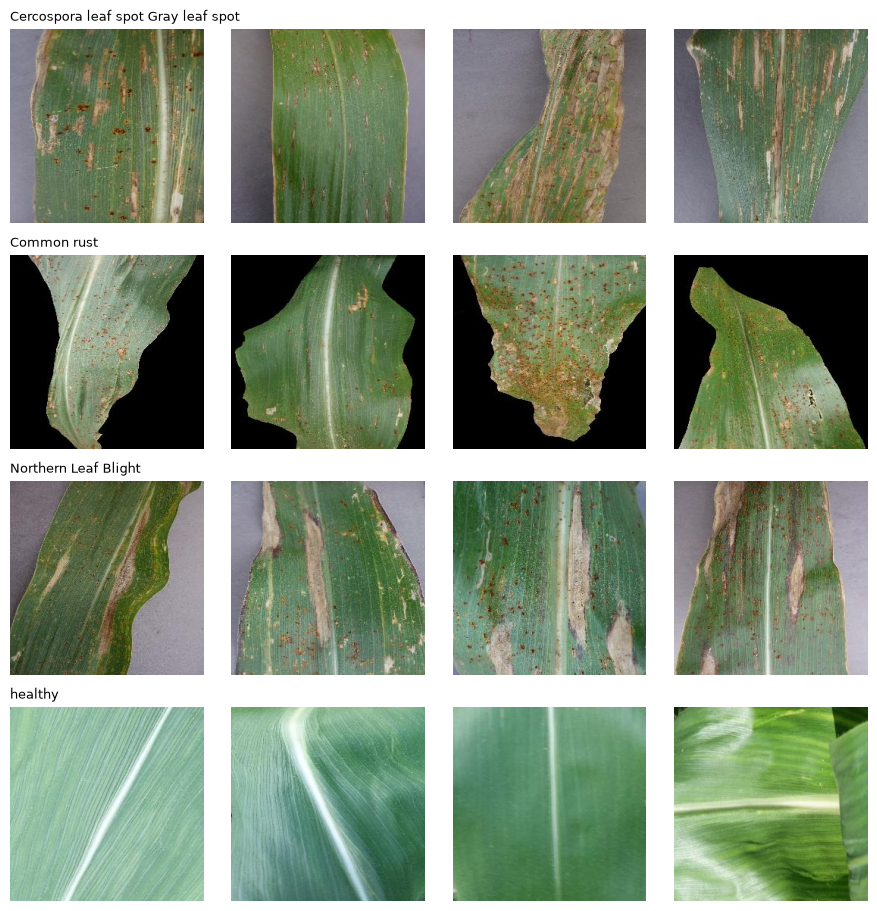

In [3]:
# Exemplos de imagens de cada classe (conjunto de treino)
fig, eixos = plt.subplots(len(CLASSES), 4, figsize=(9, 2.3 * len(CLASSES)))
for i, classe in enumerate(CLASSES):
    amostra = treino[treino.classe == classe].sample(4, random_state=SEMENTE)
    for j, caminho in enumerate(amostra.caminho):
        eixos[i, j].imshow(Image.open(RAIZ / caminho)); eixos[i, j].axis("off")
        if j == 0: eixos[i, j].set_title(curto(classe), loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 2. Pré-processamento e aumento de dados
**Pré-processamento (igual ao do app):** `app/inferencia.py` faz `Image.open(...).convert("RGB").resize((224, 224))`,
divide por 255, normaliza com média/desvio da ImageNet e converte para NCHW. Usamos **exatamente a mesma**
transformação na validação, no teste e na exportação, para que o modelo veja no app o mesmo tipo de entrada que viu aqui.

**Aumento de dados (só no treino):** rotação, espelhamento horizontal/vertical, pequeno recorte/zoom e variação de
brilho/contraste. Ele é aplicado *em memória*, a cada época, somente nas imagens de treino: validação e teste nunca
são alterados, e como a divisão foi feita antes, nenhuma versão aumentada de uma imagem de teste entra no treino.

In [4]:
TAM = 224
MEDIA, DESVIO = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet (mesmos valores do app)

class RedimensionarComoApp:
    """Redimensiona com PIL.Image.resize((224, 224)), igual a app/inferencia.preprocessar_imagem."""
    def __call__(self, img):
        return img.resize((TAM, TAM))

tf_avaliacao = transforms.Compose([
    RedimensionarComoApp(), transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIO)])

tf_treino = transforms.Compose([
    transforms.RandomResizedCrop(TAM, scale=(0.8, 1.0)),       # pequeno zoom/recorte
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.25, contrast=0.2, saturation=0.15),
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIO)])

class FolhasDataset(Dataset):
    def __init__(self, df, transform):
        self.caminhos = [RAIZ / c for c in df.caminho]; self.rotulos = [IDX[c] for c in df.classe]
        self.transform = transform
    def __len__(self): return len(self.caminhos)
    def __getitem__(self, i):
        return self.transform(Image.open(self.caminhos[i]).convert("RGB")), self.rotulos[i]

LOTE = 32
g = torch.Generator().manual_seed(SEMENTE)
dl_treino = DataLoader(FolhasDataset(treino, tf_treino), batch_size=LOTE, shuffle=True, num_workers=4, generator=g)
dl_val = DataLoader(FolhasDataset(validacao, tf_avaliacao), batch_size=64, num_workers=4)
dl_teste = DataLoader(FolhasDataset(teste, tf_avaliacao), batch_size=64, num_workers=4)
print(len(dl_treino.dataset), len(dl_val.dataset), len(dl_teste.dataset))

2696 578 578


## 3. Modelo: MobileNetV2 com transferência de aprendizado
A MobileNetV2 (Sandler et al., 2018) foi pré-treinada na ImageNet (1,2 milhão de imagens, 1000 classes) e já
sabe extrair bordas, texturas e formas. Trocamos apenas a **última camada** (1000 → 4 saídas).

Treino em **2 etapas** (Seção 4.2 do plano):
1. **Etapa 1 – só a cabeça:** todas as camadas convolucionais congeladas; treina apenas o classificador final.
2. **Etapa 2 – ajuste fino leve:** descongela os últimos blocos convolucionais e treina com taxa de aprendizado 10× menor.

As camadas de *BatchNorm* ficam sempre em modo de avaliação (estatísticas da ImageNet), prática comum com bases pequenas.
O melhor modelo é escolhido pelo **F1 macro na validação** (o teste não é usado para nenhuma escolha).

In [5]:
modelo = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
modelo.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(modelo.last_channel, len(CLASSES)))
modelo = modelo.to(DISPOSITIVO)

# Pesos de classe inversamente proporcionais à frequência no TREINO efetivamente usado
freq = treino.classe.value_counts().reindex(CLASSES).values.astype(float)
pesos_classe = torch.tensor(freq.sum() / (len(CLASSES) * freq), dtype=torch.float32, device=DISPOSITIVO)
criterio = nn.CrossEntropyLoss(weight=pesos_classe)
print("Pesos de classe:", {curto(c): round(float(w), 3) for c, w in zip(CLASSES, pesos_classe.cpu())})

def modo_treino(m):
    m.train()
    for camada in m.modules():           # BatchNorm sempre congelado
        if isinstance(camada, nn.BatchNorm2d): camada.eval()

@torch.no_grad()
def prever(m, dl):
    m.eval(); probs, y = [], []
    for x, rot in dl:
        probs.append(torch.softmax(m(x.to(DISPOSITIVO)), 1).cpu()); y.append(rot)
    return torch.cat(probs).numpy(), torch.cat(y).numpy()

historico = []
melhor = {"f1": -1, "estado": None, "epoca": None}

def treinar(m, otimizador, epocas, etapa):
    for ep in range(1, epocas + 1):
        t0 = time.time(); modo_treino(m); perda_total, acertos, n = 0.0, 0, 0
        for x, rot in dl_treino:
            x, rot = x.to(DISPOSITIVO), rot.to(DISPOSITIVO)
            otimizador.zero_grad(); saida = m(x); perda = criterio(saida, rot)
            perda.backward(); otimizador.step()
            perda_total += perda.item() * len(rot); acertos += (saida.argmax(1) == rot).sum().item(); n += len(rot)
        p_val, y_val = prever(m, dl_val)
        perda_val = criterio(torch.tensor(np.log(p_val + 1e-9)), torch.tensor(y_val)).item()  # perda ponderada na validação
        acc_val = accuracy_score(y_val, p_val.argmax(1)); f1_val = f1_score(y_val, p_val.argmax(1), average="macro")
        historico.append({"etapa": etapa, "epoca": len(historico) + 1, "perda_treino": perda_total / n,
                          "acc_treino": acertos / n, "perda_val": perda_val, "acc_val": acc_val, "f1_macro_val": f1_val})
        if f1_val > melhor["f1"]:
            melhor.update(f1=f1_val, epoca=len(historico), estado={k: v.detach().clone() for k, v in m.state_dict().items()})
        print(f"[etapa {etapa}] época {len(historico):2d} | perda {perda_total/n:.4f} acc {acertos/n:.4f} | "
              f"val perda {perda_val:.4f} acc {acc_val:.4f} F1 {f1_val:.4f} | {time.time()-t0:.0f}s")

Pesos de classe: {'Cercospora leaf spot Gray leaf spot': 1.877, 'Common rust': 0.808, 'Northern Leaf Blight': 0.977, 'healthy': 0.829}


### Etapa 1 – treino apenas da camada final (backbone congelado)

In [6]:
HP = {"lote": LOTE, "epocas_etapa1": 6, "lr_etapa1": 1e-3, "epocas_etapa2": 6, "lr_etapa2": 1e-4,
      "blocos_descongelados_etapa2": 5, "otimizador": "Adam", "weight_decay": 1e-4, "dropout": 0.2,
      "tamanho_entrada": TAM, "semente": SEMENTE, "pesos_classe": "inverso da frequência",
      "treino_csv": "treino.csv"}

for p in modelo.features.parameters(): p.requires_grad = False
otim1 = torch.optim.Adam(modelo.classifier.parameters(), lr=HP["lr_etapa1"], weight_decay=HP["weight_decay"])
t_etapa1 = time.time()
treinar(modelo, otim1, HP["epocas_etapa1"], etapa=1)
print(f"Etapa 1: {(time.time()-t_etapa1)/60:.1f} min")

[etapa 1] época  1 | perda 0.5592 acc 0.8220 | val perda 0.2763 acc 0.9429 F1 0.9232 | 47s


[etapa 1] época  2 | perda 0.2858 acc 0.9169 | val perda 0.2254 acc 0.9308 F1 0.9076 | 40s


[etapa 1] época  3 | perda 0.2454 acc 0.9258 | val perda 0.2216 acc 0.9464 F1 0.9235 | 38s


[etapa 1] época  4 | perda 0.2219 acc 0.9329 | val perda 0.1893 acc 0.9360 F1 0.9145 | 45s


[etapa 1] época  5 | perda 0.1913 acc 0.9429 | val perda 0.1891 acc 0.9394 F1 0.9186 | 40s


[etapa 1] época  6 | perda 0.1887 acc 0.9399 | val perda 0.1954 acc 0.9533 F1 0.9346 | 40s
Etapa 1: 4.2 min


### Etapa 2 – ajuste fino leve (últimos 5 blocos convolucionais + cabeça, taxa de aprendizado 10× menor)

In [7]:
for p in modelo.features[-HP["blocos_descongelados_etapa2"]:].parameters(): p.requires_grad = True
treinaveis = [p for p in modelo.parameters() if p.requires_grad]
print(f"Parâmetros treináveis: {sum(p.numel() for p in treinaveis):,} de {sum(p.numel() for p in modelo.parameters()):,}")
otim2 = torch.optim.Adam(treinaveis, lr=HP["lr_etapa2"], weight_decay=HP["weight_decay"])
t_etapa2 = time.time()
treinar(modelo, otim2, HP["epocas_etapa2"], etapa=2)
print(f"Etapa 2: {(time.time()-t_etapa2)/60:.1f} min")

# Restaura o melhor modelo segundo o F1 macro da VALIDAÇÃO
modelo.load_state_dict(melhor["estado"])
print(f"Melhor época (validação): {melhor['epoca']} | F1 macro val = {melhor['f1']:.4f}")

Parâmetros treináveis: 1,686,468 de 2,228,996


[etapa 2] época  7 | perda 0.2935 acc 0.9058 | val perda 0.3641 acc 0.9377 F1 0.9016 | 33s


[etapa 2] época  8 | perda 0.1748 acc 0.9418 | val perda 0.0995 acc 0.9671 F1 0.9553 | 36s


[etapa 2] época  9 | perda 0.1373 acc 0.9585 | val perda 0.1028 acc 0.9706 F1 0.9597 | 35s


[etapa 2] época 10 | perda 0.1173 acc 0.9592 | val perda 0.0972 acc 0.9637 F1 0.9531 | 37s


[etapa 2] época 11 | perda 0.0999 acc 0.9700 | val perda 0.1425 acc 0.9516 F1 0.9429 | 35s


[etapa 2] época 12 | perda 0.1153 acc 0.9648 | val perda 0.0942 acc 0.9740 F1 0.9630 | 35s
Etapa 2: 3.5 min
Melhor época (validação): 12 | F1 macro val = 0.9630


### Curvas de treinamento
A linha tracejada separa a etapa 1 (só cabeça) da etapa 2 (ajuste fino).

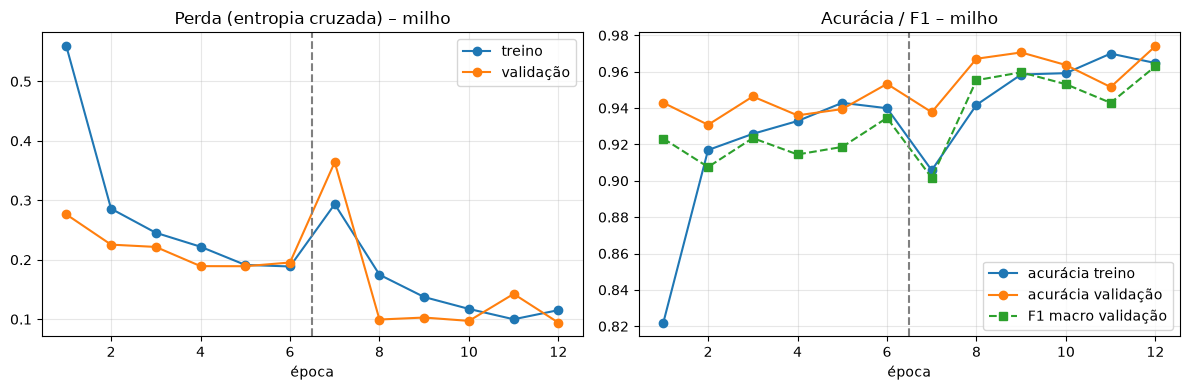

,etapa,epoca,perda_treino,acc_treino,perda_val,acc_val,f1_macro_val
0,1,1,0.559243,0.821958,0.276266,0.942907,0.923204
1,1,2,0.285844,0.916914,0.225436,0.930796,0.907571
2,1,3,0.245390,0.925816,0.221554,0.946367,0.923486
3,1,4,0.221934,0.932864,0.189259,0.935986,0.914489
4,1,5,0.191332,0.942878,0.189116,0.939446,0.918629
5,1,6,0.188709,0.939911,0.195372,0.953287,0.934597
6,2,7,0.293483,0.905786,0.364129,0.937716,0.901611
7,2,8,0.174829,0.941766,0.099461,0.967128,0.955324
8,2,9,0.137275,0.958457,0.102812,0.970588,0.959666
9,2,10,0.117299,0.959199,0.097157,0.963668,0.953103


In [8]:
h = pd.DataFrame(historico)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(h.epoca, h.perda_treino, "o-", label="treino"); a1.plot(h.epoca, h.perda_val, "o-", label="validação")
a1.set_title("Perda (entropia cruzada) – milho"); a1.set_xlabel("época")
a2.plot(h.epoca, h.acc_treino, "o-", label="acurácia treino"); a2.plot(h.epoca, h.acc_val, "o-", label="acurácia validação")
a2.plot(h.epoca, h.f1_macro_val, "s--", label="F1 macro validação"); a2.set_title("Acurácia / F1 – milho"); a2.set_xlabel("época")
for a in (a1, a2):
    a.axvline(HP["epocas_etapa1"] + 0.5, color="gray", ls="--"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(MODELOS / f"curvas_treino_{PLANTA}.png", dpi=120); plt.show()
h

## 4. Calibração do limiar de confiança (na VALIDAÇÃO)
O app combina as 3 folhas: se alguma foto tiver confiança abaixo do **limiar**, ele pede novas fotos (status `incerto`).
Calibramos esse limiar **na validação** (nunca no teste). Para cada limiar candidato calculamos:
* **cobertura**: fração de fotos aceitas (confiança ≥ limiar);
* **acurácia das aceitas**: acurácia apenas nas fotos aceitas.

Regra de escolha (a mesma para todas as plantas): entre os limiares que mantêm **cobertura ≥ 97%** na validação, escolhemos o de
**maior acurácia das aceitas**; em caso de empate, o **maior** limiar (mais cauteloso). O valor é salvo em `modelos/metricas_milho.json`.

Acurácia na validação (sem limiar): 0.9740
Limiar escolhido: 0.69
 limiar  cobertura  acuracia_aceitas  erros_aceitos
   0.50   1.000000          0.974048             15
   0.60   0.993080          0.977352             13
   0.69   0.972318          0.985765              8
   0.70   0.970588          0.985740              8
   0.80   0.948097          0.990876              5
   0.90   0.915225          0.996219              2
   0.95   0.885813          1.000000              0
   0.99   0.799308          1.000000              0


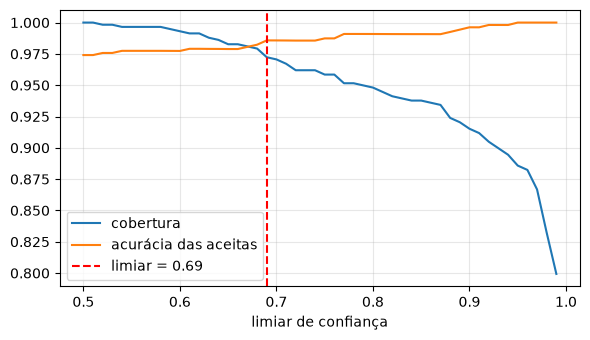

In [9]:
p_val, y_val = prever(modelo, dl_val)
conf_val, pred_val = p_val.max(1), p_val.argmax(1)
linhas = []
for t in np.round(np.arange(0.50, 0.991, 0.01), 2):
    aceita = conf_val >= t
    linhas.append({"limiar": t, "cobertura": aceita.mean(),
                   "acuracia_aceitas": (pred_val[aceita] == y_val[aceita]).mean() if aceita.any() else np.nan,
                   "erros_aceitos": int(((pred_val != y_val) & aceita).sum())})
tab_limiar = pd.DataFrame(linhas)
candidatos = tab_limiar[tab_limiar.cobertura >= 0.97]
melhor_acc = candidatos.acuracia_aceitas.max()
LIMIAR = float(candidatos[candidatos.acuracia_aceitas == melhor_acc].limiar.max())
print(f"Acurácia na validação (sem limiar): {accuracy_score(y_val, pred_val):.4f}")
print(f"Limiar escolhido: {LIMIAR:.2f}")
print(tab_limiar[tab_limiar.limiar.isin([0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, LIMIAR])].to_string(index=False))

fig, a = plt.subplots(figsize=(6, 3.5))
a.plot(tab_limiar.limiar, tab_limiar.cobertura, label="cobertura"); a.plot(tab_limiar.limiar, tab_limiar.acuracia_aceitas, label="acurácia das aceitas")
a.axvline(LIMIAR, color="red", ls="--", label=f"limiar = {LIMIAR:.2f}"); a.set_xlabel("limiar de confiança"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Avaliação final no conjunto de TESTE (usado uma única vez)
Até aqui o teste não foi usado para nada. Agora avaliamos uma única vez o modelo escolhido, com **todas** as imagens de teste.
As métricas são calculadas **por imagem**:
* **Precisão** de uma classe: das imagens que o modelo disse ser daquela classe, quantas eram de fato.
* **Revocação** (*recall*): das imagens que eram daquela classe, quantas o modelo encontrou.
* **F1**: média harmônica entre precisão e revocação.
* **Macro**: média simples entre as classes, que dá o mesmo peso às classes minoritárias.

                                                    precision    recall  f1-score   support

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9420    0.8442    0.8904        77
                       Corn_(maize)___Common_rust_     1.0000    1.0000    1.0000       179
               Corn_(maize)___Northern_Leaf_Blight     0.9226    0.9662    0.9439       148
                            Corn_(maize)___healthy     0.9943    1.0000    0.9971       174

                                          accuracy                         0.9706       578
                                         macro avg     0.9647    0.9526    0.9579       578
                                      weighted avg     0.9707    0.9706    0.9702       578



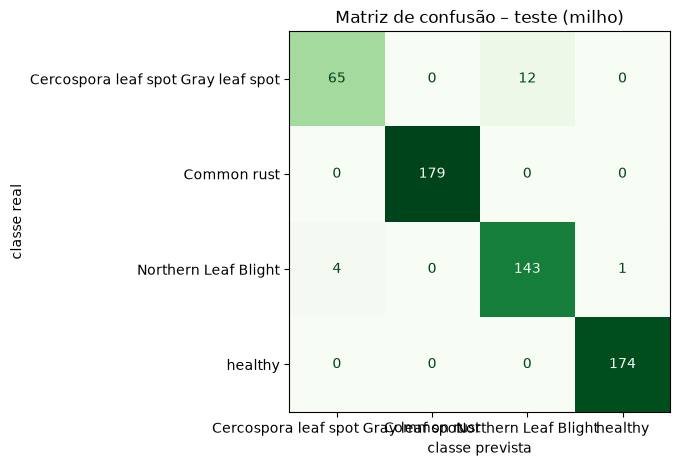

Com o limiar 0.69: 97.2% das fotos de teste aceitas; acurácia nas aceitas = 0.9822


In [10]:
p_teste, y_teste = prever(modelo, dl_teste)
pred_teste = p_teste.argmax(1)
print(classification_report(y_teste, pred_teste, labels=range(len(CLASSES)), target_names=CLASSES, digits=4, zero_division=0))
relatorio = classification_report(y_teste, pred_teste, labels=range(len(CLASSES)), target_names=CLASSES, digits=4,
                                  output_dict=True, zero_division=0)
mc = confusion_matrix(y_teste, pred_teste, labels=range(len(CLASSES)))

fig, a = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(mc, display_labels=[curto(c) for c in CLASSES]).plot(ax=a, cmap="Greens", colorbar=False,
                                                                            xticks_rotation=45 if len(CLASSES) > 4 else "horizontal")
a.set_title(f"Matriz de confusão – teste ({PLANTA})"); a.set_xlabel("classe prevista"); a.set_ylabel("classe real")
plt.tight_layout(); plt.savefig(MODELOS / f"matriz_confusao_{PLANTA}.png", dpi=150); plt.show()

aceita_t = p_teste.max(1) >= LIMIAR
print(f"Com o limiar {LIMIAR:.2f}: {aceita_t.mean():.1%} das fotos de teste aceitas; "
      f"acurácia nas aceitas = {(pred_teste[aceita_t] == y_teste[aceita_t]).mean():.4f}")

17 erro(s) em 578 imagens de teste


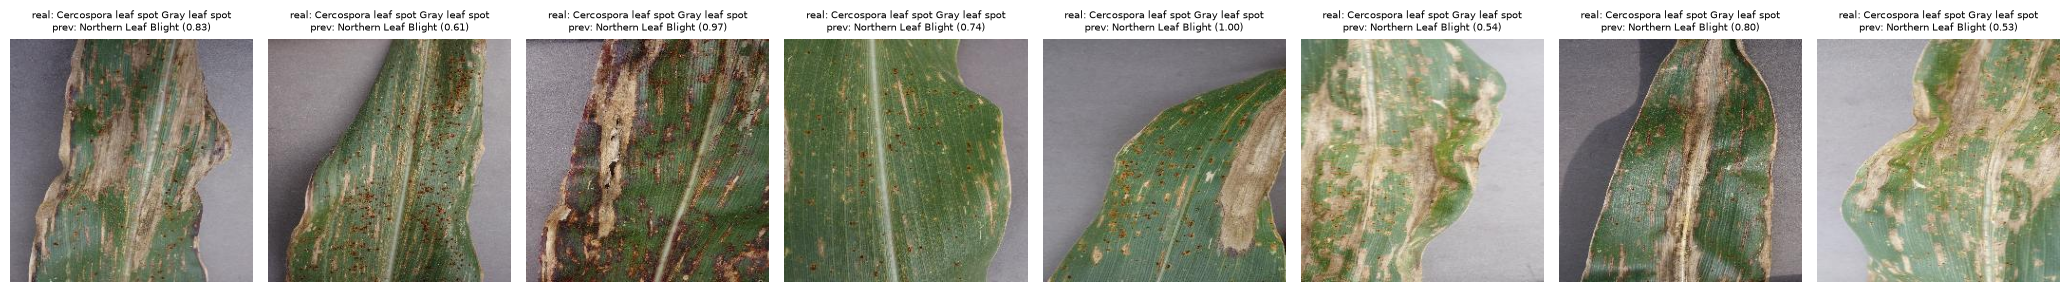

In [11]:
# Imagens de teste classificadas erradamente (até 8 exemplos)
erros = np.where(pred_teste != y_teste)[0]
print(f"{len(erros)} erro(s) em {len(y_teste)} imagens de teste")
if len(erros):
    n = min(len(erros), 8)
    fig, eixos = plt.subplots(1, n, figsize=(2.6 * n, 3.2), squeeze=False)
    for a, i in zip(eixos[0], erros[:n]):
        a.imshow(Image.open(RAIZ / teste.caminho.iloc[i])); a.axis("off")
        a.set_title(f"real: {curto(CLASSES[y_teste[i]])}\nprev: {curto(CLASSES[pred_teste[i]])} ({p_teste[i].max():.2f})", fontsize=7)
    plt.tight_layout(); plt.show()

## 6. Exportação para ONNX (`modelos/milho.onnx`)
Mesmo formato do modelo da batata, que é o que `app/inferencia.py` usa: entrada `input` com forma `(lote, 3, 224, 224)` normalizada (ImageNet)
e saída `logits` (o app aplica **softmax**). As classes ficam na ordem da lista `CLASSES` acima. O eixo do lote é dinâmico.

In [12]:
modelo_cpu = modelo.to("cpu").eval()
exemplo = torch.randn(1, 3, TAM, TAM)
CAMINHO_ONNX = MODELOS / f"{PLANTA}.onnx"
torch.onnx.export(modelo_cpu, exemplo, CAMINHO_ONNX, input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "lote"}, "logits": {0: "lote"}}, opset_version=17, dynamo=False)
print(f"{CAMINHO_ONNX} – {CAMINHO_ONNX.stat().st_size / 1e6:.1f} MB")

/tmp/ipykernel_32219/3526002041.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(modelo_cpu, exemplo, CAMINHO_ONNX, input_names=["input"], output_names=["logits"],


/workspace/planthealth/modelos/milho.onnx – 8.9 MB


### Verificação: ONNX × PyTorch, usando o pré-processamento do próprio app
Importamos `preprocessar_imagem` e `softmax` de `app/inferencia.py` (apenas leitura, sem modificar o app) e comparamos,
em **todas** as imagens de teste, as probabilidades do ONNX Runtime com as do modelo PyTorch.

In [13]:
import sys, onnxruntime as ort
sys.path.insert(0, str(RAIZ))
sys.dont_write_bytecode = True          # não gera __pycache__ dentro de app/
from app.inferencia import preprocessar_imagem, softmax as softmax_app
print("Observação: app/inferencia.py só define CLASSES_BATATA; não há lista de classes do app para esta planta.")

sessao = ort.InferenceSession(str(CAMINHO_ONNX), providers=["CPUExecutionProvider"])
print("Entrada ONNX:", sessao.get_inputs()[0].name, sessao.get_inputs()[0].shape, "| saída:", sessao.get_outputs()[0].shape)
dif_max, concordam = 0.0, 0
pred_onnx = []
for caminho in teste.caminho:
    x = preprocessar_imagem(str(RAIZ / caminho))                         # pré-processamento do APP
    p_onnx = softmax_app(sessao.run(None, {"input": x})[0][0])
    with torch.no_grad():
        p_torch = torch.softmax(modelo_cpu(torch.from_numpy(x)), 1)[0].numpy()
    dif_max = max(dif_max, float(np.abs(p_onnx - p_torch).max()))
    concordam += int(p_onnx.argmax() == p_torch.argmax()); pred_onnx.append(int(p_onnx.argmax()))
pred_onnx = np.array(pred_onnx)
print(f"Diferença máxima de probabilidade ONNX × PyTorch: {dif_max:.2e}")
print(f"Mesma classe prevista em {concordam}/{len(teste)} imagens")
print(f"Acurácia do ONNX (pré-processamento do app) no teste: {accuracy_score(y_teste, pred_onnx):.4f}")
for caminho, real, prev in list(zip(teste.caminho, y_teste, pred_onnx))[::max(1, len(teste) // 6)]:
    print(f"  {Path(caminho).name[:40]:40s} real={curto(CLASSES[real]):28s} onnx={curto(CLASSES[prev])}")

Observação: app/inferencia.py só define CLASSES_BATATA; não há lista de classes do app para esta planta.
Entrada ONNX: input ['lote', 3, 224, 224] | saída: ['lote', 4]


Diferença máxima de probabilidade ONNX × PyTorch: 1.58e-06
Mesma classe prevista em 578/578 imagens
Acurácia do ONNX (pré-processamento do app) no teste: 0.9706
  01a02916-5d4c-4256-936b-6b1a9ee65b11___R real=Cercospora leaf spot Gray leaf spot onnx=Cercospora leaf spot Gray leaf spot
  RS_Rust 1669.JPG                         real=Common rust                  onnx=Common rust
  RS_Rust 2339.JPG                         real=Common rust                  onnx=Common rust
  3fdd99f1-a3df-4498-8b6a-b844621a72ca___R real=Northern Leaf Blight         onnx=Northern Leaf Blight
  da24c7cf-a119-46e9-b34a-049d21fe610c___R real=Northern Leaf Blight         onnx=Northern Leaf Blight
  70381b2f-7964-4252-a44a-f63a2c35a71c___R real=healthy                      onnx=healthy
  f741de14-0e76-4922-8c59-3281d55f019a___R real=healthy                      onnx=healthy


## 7. Salvando as métricas (`modelos/metricas_milho.json`)
O JSON também traz os campos no formato do endpoint `/api/colab/registrar-modelo` do app (não é enviado automaticamente).

In [14]:
prec, rev, f1c, sup = precision_recall_fscore_support(y_teste, pred_teste, labels=range(len(CLASSES)), zero_division=0)
por_classe = {c: {"precisao": float(prec[i]), "revocacao": float(rev[i]), "f1": float(f1c[i]), "suporte": int(sup[i])}
              for i, c in enumerate(CLASSES)}
tempo_total_min = (time.time() - INICIO) / 60
metricas = {
    "planta": PLANTA, "versao": "v1", "arquitetura": "MobileNetV2 (ImageNet, transferência de aprendizado)",
    "treinado_em": pd.Timestamp.now(tz="UTC").isoformat(), "classes": CLASSES, "limiar": LIMIAR,
    "ambiente": {"plataforma": "cpu" if DISPOSITIVO.type == "cpu" else "gpu", "torch": torch.__version__,
                 "threads": torch.get_num_threads(), "tempo_total_min": round(tempo_total_min, 1)},
    "divisao": {"treino": len(treino_completo), "treino_usado": len(treino), "validacao": len(validacao), "teste": len(teste),
                "proporcao": "70/15/15 estratificada", "semente": SEMENTE, "arquivo_treino": HP["treino_csv"]},
    "hiperparametros": HP, "melhor_epoca_validacao": melhor["epoca"],
    "teste": {"acuracia": float(accuracy_score(y_teste, pred_teste)),
              "precisao_macro": float(relatorio["macro avg"]["precision"]),
              "revocacao_macro": float(relatorio["macro avg"]["recall"]),
              "f1_macro": float(relatorio["macro avg"]["f1-score"]),
              "f1_ponderado": float(relatorio["weighted avg"]["f1-score"]),
              "por_classe": por_classe,
              "com_limiar": {"cobertura": float(aceita_t.mean()),
                             "acuracia_aceitas": float((pred_teste[aceita_t] == y_teste[aceita_t]).mean())}},
    "validacao": {"acuracia": float(accuracy_score(y_val, pred_val)), "f1_macro": float(f1_score(y_val, pred_val, average="macro"))},
    "matriz_confusao": {"classes": CLASSES, "valores": mc.tolist(), "linhas": "real", "colunas": "prevista"},
    "onnx": {"arquivo": f"modelos/{PLANTA}.onnx", "entrada": "input (lote, 3, 224, 224) float32, ImageNet",
             "saida": f"logits (lote, {len(CLASSES)}) – aplicar softmax", "dif_max_vs_pytorch": dif_max,
             "concordancia_vs_pytorch": f"{concordam}/{len(teste)}"},
    "historico": historico,
}
with open(MODELOS / f"metricas_{PLANTA}.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)
print(json.dumps({k: metricas[k] for k in ["limiar", "ambiente"]}, ensure_ascii=False, indent=2))
print(pd.DataFrame(por_classe).T.round(4).sort_values("f1"))

{
  "limiar": 0.69,
  "ambiente": {
    "plataforma": "cpu",
    "torch": "2.14.1+cpu",
    "threads": 8,
    "tempo_total_min": 8.7
  }
}
                                                    precisao  revocacao  \
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    0.9420     0.8442   
Corn_(maize)___Northern_Leaf_Blight                   0.9226     0.9662   
Corn_(maize)___healthy                                0.9943     1.0000   
Corn_(maize)___Common_rust_                           1.0000     1.0000   

                                                        f1  suporte  
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot  0.8904     77.0  
Corn_(maize)___Northern_Leaf_Blight                 0.9439    148.0  
Corn_(maize)___healthy                              0.9971    174.0  
Corn_(maize)___Common_rust_                         1.0000    179.0  


## 8. Conclusões e limitações
* O classificador do milho segue o mesmo protocolo da batata: 4 categorias, treino/validação/teste com semente fixa, matriz de confusão e métricas por classe.
* **Fotos de laboratório:** o PlantVillage foi fotografado em condições controladas. Em fotos de campo o desempenho tende a cair bastante
  (Mohanty et al., 2016). **Ainda falta avaliar fotos reais externas**, separadamente.
* **Mesma folha em várias fotos:** a base não identifica a folha de origem; só garantimos que imagens idênticas (mesmo hash) ficam no mesmo conjunto.
* **Escopo:** o modelo só conhece essas 4 condições; outras doenças, pragas ou fotos que não sejam de folha serão classificadas, erroneamente, em uma delas.